# Bayesian deep survival modelling on METABRIC

Survival models are usually asked a single question: *rank these patients by risk*. A model that
also says **how sure it is** could do something more useful — hand the cases it cannot judge back
to a clinician instead of guessing.

This notebook walks through that idea end to end on the METABRIC breast cancer cohort. A
feed-forward network is trained on 1,000 transcripts plus 12 clinical covariates with a Cox
partial-likelihood loss, and dropout is left switched on at prediction time so each patient gets a
distribution of risk scores rather than a point estimate.

The short version of what follows: the deep model does **not** beat a plain clinical Cox model here,
and the raw dropout variance turns out to be a poor confidence signal until one specific confound is
removed. Both of those are worth showing.

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

if Path.cwd().name == "notebooks":
    sys.path.insert(0, str(Path.cwd().parent))

from src.data_loader import load_metabric
from src.train import TrainConfig, run_cross_validation, configure_logging
from src.uncertainty import (
    evaluate,
    performance_table,
    residual_uncertainty,
    ipcw_brier_contributions,
    harrell_cindex,
)

configure_logging(Path("../logs/notebook.log"), verbose=False)
pd.set_option("display.width", 110)

In [ ]:
from src.visualize import set_style, COLOR_LOW, COLOR_HIGH, COLOR_RAW, COLOR_NEUTRAL

%matplotlib inline
import matplotlib.pyplot as plt

set_style()
plt.rcParams["figure.dpi"] = 100

## 1. The cohort

The cBioPortal distribution ships genes-by-samples expression alongside two clinical tables. The
loader aligns them, drops patients without follow-up, and caches the result — the first call parses
a 20k x 2k text matrix and takes about a minute.

In [ ]:
data = load_metabric("../data/brca_metabric")

print(f"patients            : {data.n_samples}")
print(f"genes               : {data.expression.shape[1]}")
print(f"clinical covariates : {data.clinical.shape[1]}")
print(f"deaths              : {int(data.event.sum())} ({100 * data.event.mean():.1f}%)")
print(f"median follow-up    : {np.median(data.time):.1f} months")

patients            : 1979
genes               : 20385
clinical covariates : 12
deaths              : 1143 (57.8%)
median follow-up    : 116.5 months


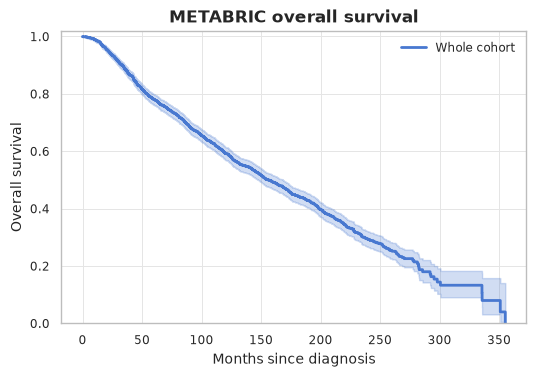

In [ ]:
from lifelines import KaplanMeierFitter

fig, ax = plt.subplots(figsize=(6, 3.8))
KaplanMeierFitter().fit(data.time, data.event).plot_survival_function(
    ax=ax, color=COLOR_LOW, linewidth=2
)
ax.set_xlabel("Months since diagnosis")
ax.set_ylabel("Overall survival")
ax.set_title("METABRIC overall survival")
ax.set_ylim(0, 1.02)
ax.legend(["Whole cohort"])
plt.show()

Follow-up runs out past 300 months and 58 % of patients died, so this is an unusually mature
survival dataset — there is real signal to fit, and censoring is not overwhelming.

## 2. Cross-validated training

Everything that touches the data is refitted inside each fold: the variance-based gene selection,
the standardiser, the network, the baseline hazard, and the clinical Cox comparator. Each training
fold is split three ways — 70 % to fit, 15 % for early stopping, 15 % reserved purely for
calibrating absolute survival probabilities.

That third split matters. Re-using the early-stopping patients to calibrate biases the baseline
hazard, because the epoch is *chosen* to look good on them.

In [ ]:
cfg = TrainConfig()
oof, folds = run_cross_validation(data, cfg)

pd.DataFrame([{
    "fold": f.fold, "best epoch": f.best_epoch,
    "val C": round(f.val_cindex, 4),
    "test C": round(f.test_cindex, 4),
    "clinical Cox C": round(f.baseline_cindex, 4),
} for f in folds])

,fold,best epoch,val C,test C,clinical Cox C
0,1,121,0.6437,0.6407,0.6759
1,2,84,0.6928,0.6663,0.6897
2,3,183,0.6745,0.6069,0.6650
3,4,100,0.6700,0.6393,0.6572
4,5,51,0.6600,0.6743,0.6834


The clinical Cox baseline beats the network in every one of the five folds. That is the first result, and
it is not an artefact of a bad run — it holds across the whole hyperparameter grid that was searched.

## 3. Headline metrics

Risk scores are standardised against each fold's calibration split before being pooled. A Cox score
is identified only up to a shift and a scale, so concatenating raw per-fold scores would compare
patients on incompatible units — worth about 0.02 C-index here.

In [ ]:
results = evaluate(oof)
performance_table(results)

,model,n,cindex,cindex_ci_low,cindex_ci_high,auc_5y,dcal_p_value,referral_gain
0,Clinical Cox baseline,,0.6741,0.6581,0.6911,0.7065,0.9472,
1,Bayesian MLP (MC Dropout),,0.6453,0.6280,0.6617,0.6863,0.8823,
2,+ Uncertainty referral (top 20% deferred),1584,0.6591,0.6398,0.6775,0.6968,,0.0136


In [ ]:
strat = results["stratification"]
print(f"hazard ratio (high vs low risk) : {strat.hazard_ratio:.2f} "
      f"({strat.hr_ci[0]:.2f}-{strat.hr_ci[1]:.2f})")
print(f"log-rank p                      : {strat.logrank_p:.3g}")
print(f"median OS, low risk             : {strat.median_survival['low_risk']:.0f} months")
print(f"median OS, high risk            : {strat.median_survival['high_risk']:.0f} months")

hazard ratio (high vs low risk) : 2.09 (1.85-2.36)
log-rank p                      : 5.31e-35
median OS, low risk             : 207 months
median OS, high risk            : 113 months


The model separates the cohort convincingly — a median-split hazard ratio above 2 — even though it
ranks patients slightly worse than the clinical model does.

## 4. Is the survival curve calibrated?

Discrimination says nothing about whether a predicted 5-year survival of 0.8 means 80 %. The
D-calibration test asks whether $\hat{S}(T_i \mid x_i)$ is uniform across patients; a **large**
p-value is the good outcome.

The network needed a shrinkage step to get there. Its raw risk scores are heavily over-dispersed —
the fitted van Houwelingen calibration slopes are 0.20-0.51 per fold, against 0.94-1.53 for the Cox
comparator — and without correcting for that, D-calibration is rejected outright.

In [ ]:
for label, key in [("Bayesian MLP", "bayesian"), ("Clinical Cox", "baseline")]:
    d = results[key]["dcal"]
    print(f"{label:<14} chi2 = {d.chi2:6.2f}  p = {d.p_value:.3f}")

Bayesian MLP   chi2 =   4.41  p = 0.882
Clinical Cox   chi2 =   3.38  p = 0.947


## 5. Does the uncertainty mean anything?

This is the part worth dwelling on. The obvious move is to rank patients by the spread $\sigma$ of
their MC-dropout risk scores and defer the widest ones. It does not work — and the reason is
instructive.

In [ ]:
risk = oof["risk_z"].to_numpy()
sigma = oof["sigma_z"].to_numpy()
fold = oof["fold"].to_numpy()

print(f"corr(sigma, |risk|) = {np.corrcoef(sigma, np.abs(risk))[0, 1]:+.3f}")
print(f"corr(sigma,  risk ) = {np.corrcoef(sigma, risk)[0, 1]:+.3f}")

corr(sigma, |risk|) = +0.481
corr(sigma,  risk ) = -0.447


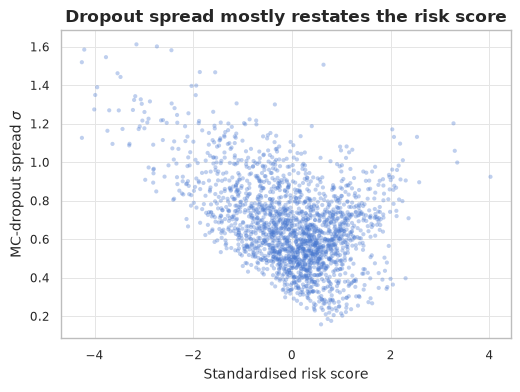

In [ ]:
fig, ax = plt.subplots(figsize=(5.8, 4))
ax.scatter(risk, sigma, s=9, alpha=0.35, color=COLOR_LOW, edgecolors="none")
ax.set_xlabel("Standardised risk score")
ax.set_ylabel(r"MC-dropout spread $\sigma$")
ax.set_title("Dropout spread mostly restates the risk score")
plt.show()

Dropout noise propagates roughly in proportion to how far a prediction sits from the cohort centre,
so $\sigma$ is largely a restatement of $|\text{risk}|$. Patients at the extremes of the risk scale
are the *easiest* to rank, so deferring them removes the cases the C-index rewards most.

Regressing $\sigma$ on a quadratic in the risk score, fold by fold, and keeping the residual leaves
the part of the spread that is not explained by position on the risk scale. No survival outcome
enters that adjustment, so it cannot leak label information.

In [ ]:
sigma_resid = residual_uncertainty(sigma, risk, fold)
brier = ipcw_brier_contributions(oof["surv_at_5y"].to_numpy(),
                                 oof["time"].to_numpy(), oof["event"].to_numpy())

comparison = pd.DataFrame({
    "tercile": ["low", "medium", "high"],
    "Brier, raw sigma": [
        brier[pd.qcut(sigma, 3, labels=False) == b].mean() for b in range(3)
    ],
    "Brier, risk-adjusted sigma": [
        brier[pd.qcut(sigma_resid, 3, labels=False) == b].mean() for b in range(3)
    ],
}).round(4)
comparison

,tercile,"Brier, raw sigma","Brier, risk-adjusted sigma"
0,low,0.1532,0.1354
1,medium,0.1764,0.1555
2,high,0.1455,0.1841


Read the two columns side by side. Under raw $\sigma$ the "most uncertain" third has the *lowest*
error — the signal points backwards. Under risk-adjusted $\sigma$ the error climbs monotonically,
which is what a usable confidence estimate should look like.

The referral curve makes the same point in the units a clinician would care about.

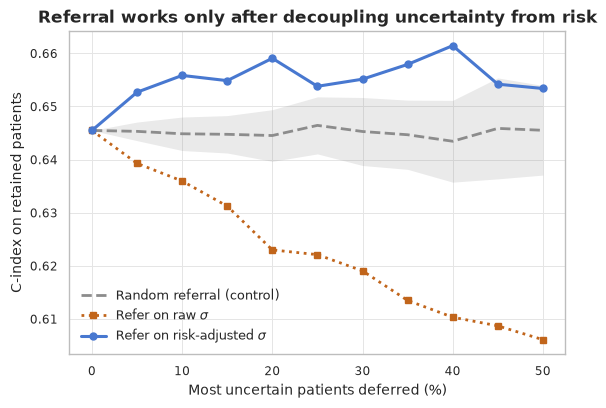

In [ ]:
curve_adj = results["referral_curve"]
curve_raw = results["referral_curve_raw"]

fig, ax = plt.subplots(figsize=(6.4, 4.2))
x = curve_adj["referral_fraction"] * 100
ax.fill_between(x,
                curve_adj["cindex_random_referral"] - curve_adj["cindex_random_sd"],
                curve_adj["cindex_random_referral"] + curve_adj["cindex_random_sd"],
                color=COLOR_NEUTRAL, alpha=0.18, linewidth=0)
ax.plot(x, curve_adj["cindex_random_referral"], "--", color=COLOR_NEUTRAL, lw=2,
        label="Random referral (control)")
ax.plot(curve_raw["referral_fraction"] * 100, curve_raw["cindex_uncertainty_referral"],
        ":", marker="s", ms=4, color=COLOR_RAW, lw=2, label=r"Refer on raw $\sigma$")
ax.plot(x, curve_adj["cindex_uncertainty_referral"], marker="o", ms=5,
        color=COLOR_LOW, lw=2.2, label=r"Refer on risk-adjusted $\sigma$")
ax.set_xlabel("Most uncertain patients deferred (%)")
ax.set_ylabel("C-index on retained patients")
ax.set_title("Referral works only after decoupling uncertainty from risk")
ax.legend(loc="lower left", fontsize=9)
plt.show()

## 6. What the model actually uses

The full ranking lives in `results/tables/feature_importance.csv`; the figure below is regenerated by
`python -m src.visualize`. Clinical covariates take the first seven ranks, which is consistent with
the network failing to beat the clinical Cox model — most of what it has learned *is* the clinical
model, plus a modest transcriptomic increment.

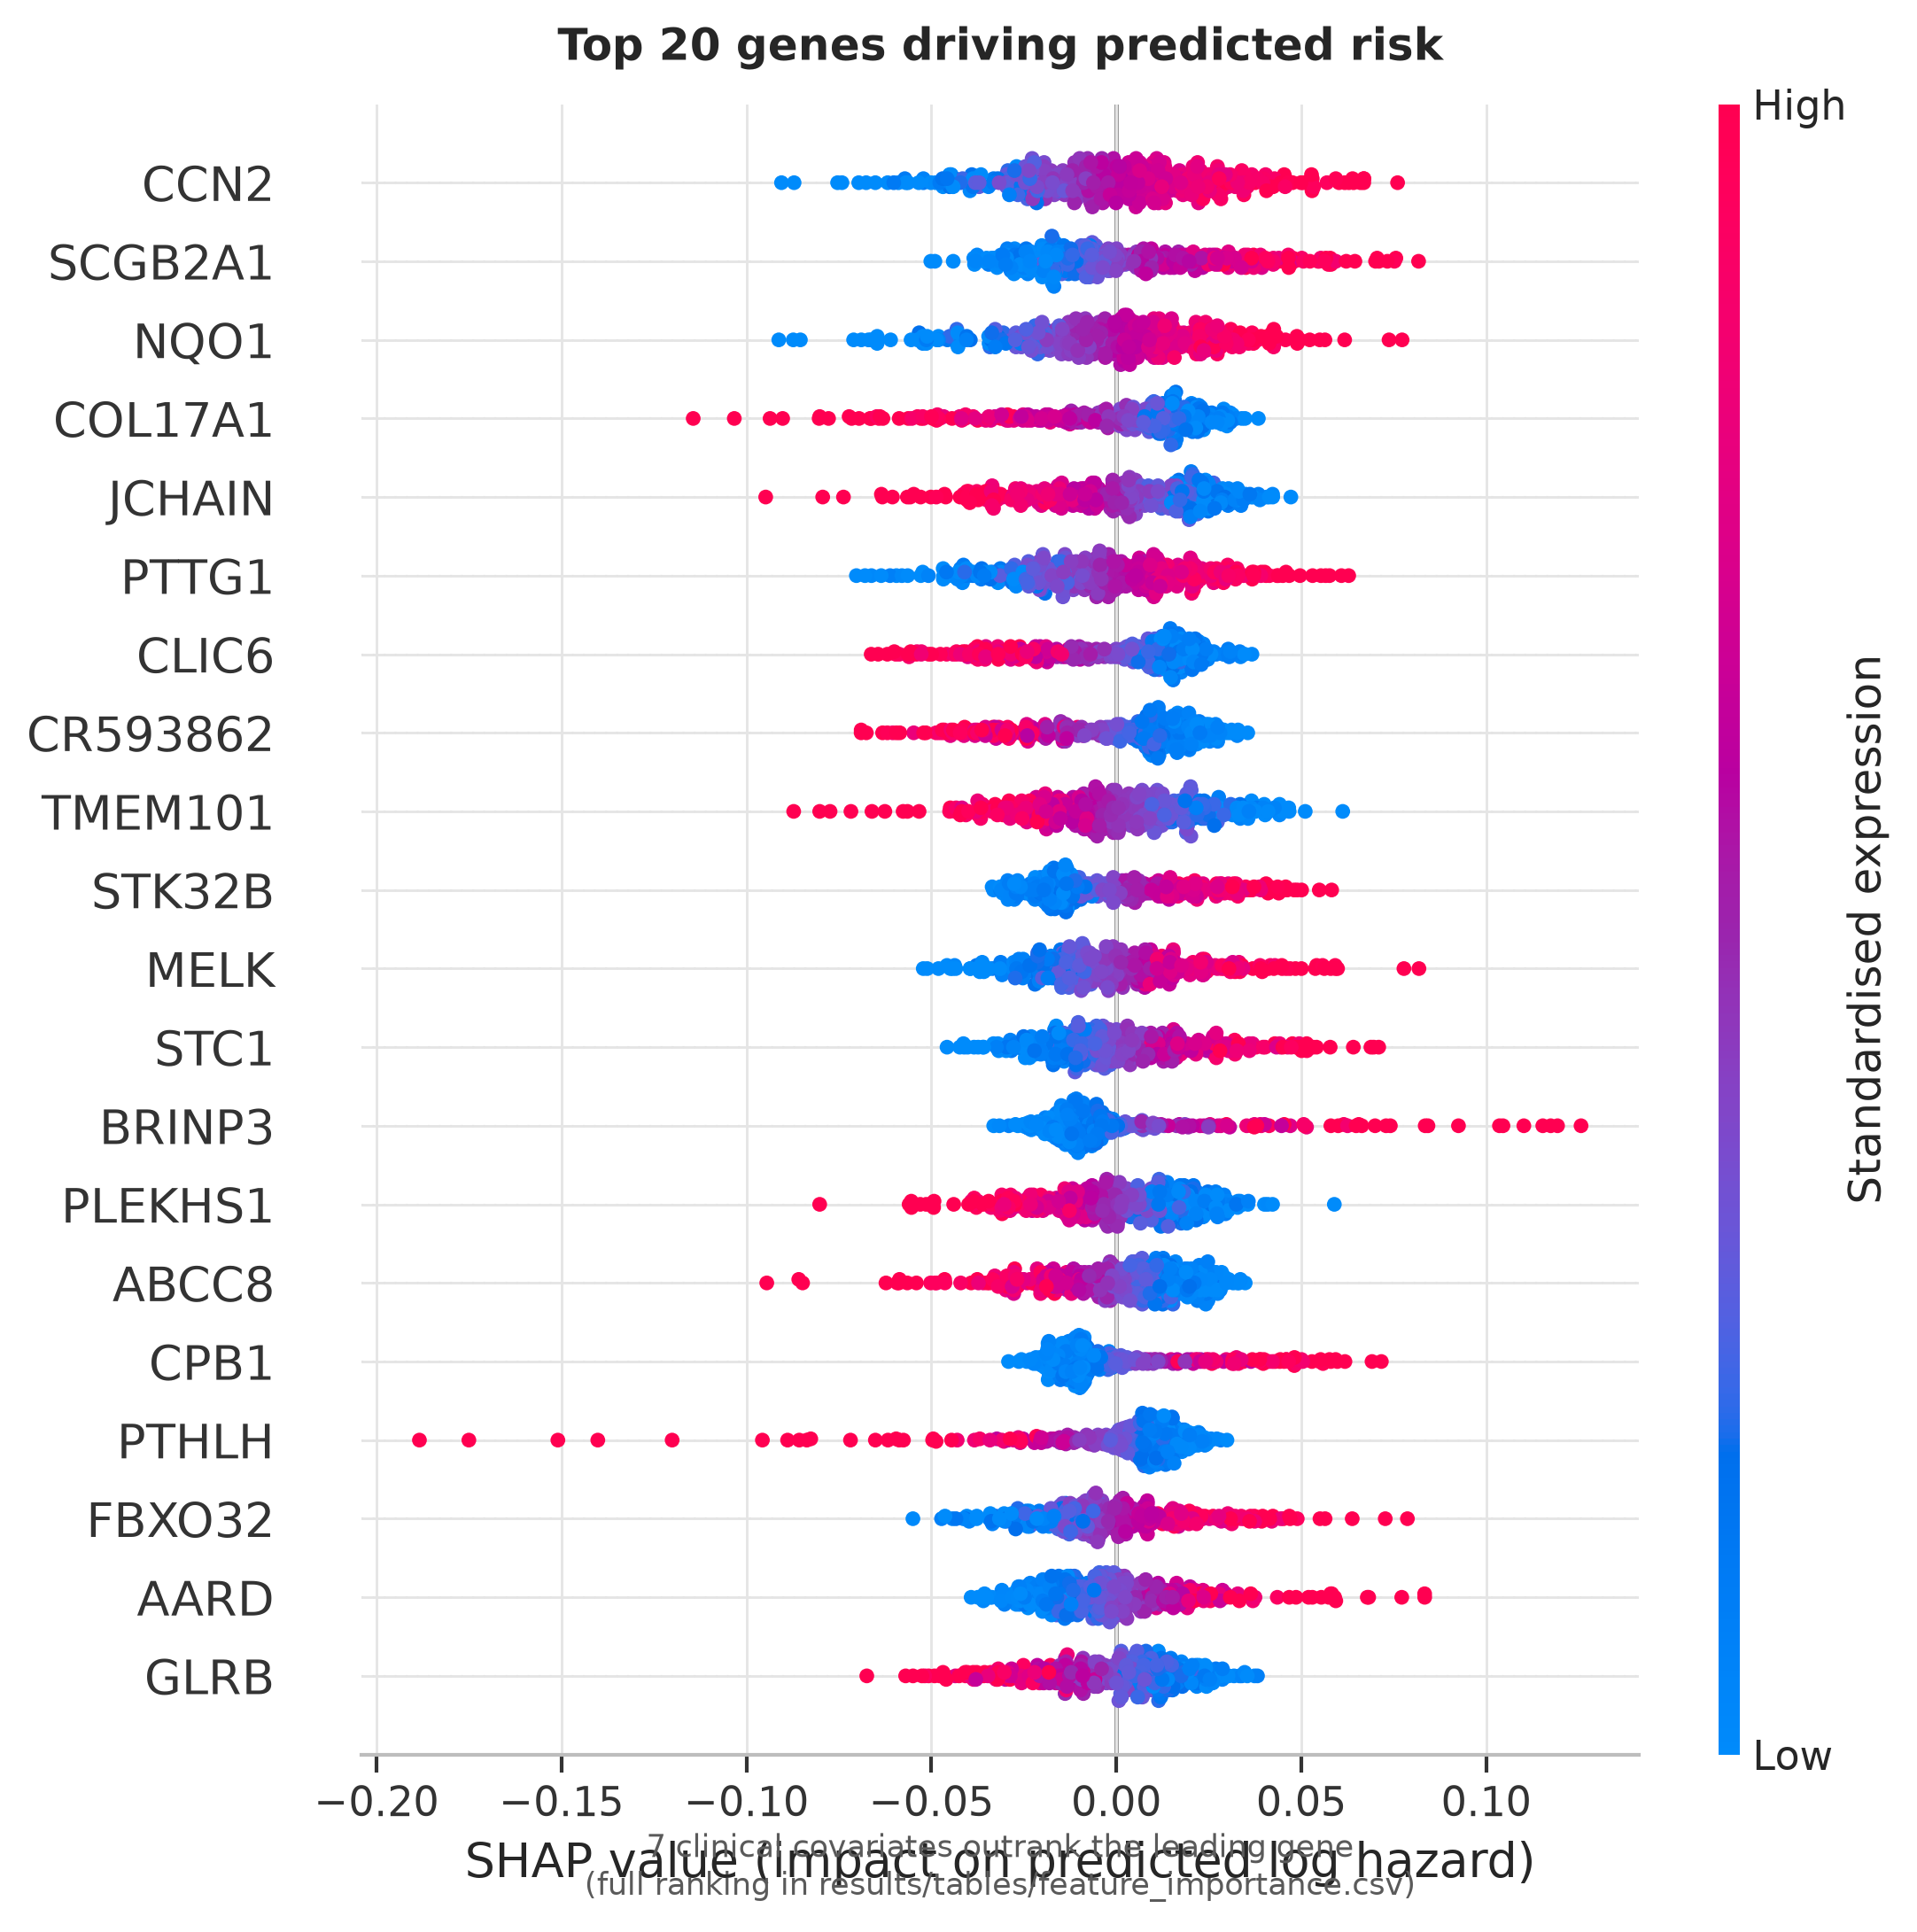

In [ ]:
from IPython.display import Image
Image(filename="../results/figures/shap_summary.png", width=620)

## 7. Where this leaves things

- A transcriptome-wide Bayesian MLP reached **C = 0.645** out-of-fold against **0.674** for a
  12-variable clinical Cox model. On this cohort, for overall survival, the extra 1,000 features did
  not pay for themselves.
- Its survival probabilities are trustworthy only after an explicit shrinkage step. Calibration
  slopes near 0.3 are a blunt statement that the network over-fits 1.3k training patients.
- Raw MC-dropout variance is confounded with prediction magnitude and is actively misleading as a
  referral signal. Once decoupled, deferring the least-certain 20 % lifts the C-index on the
  remainder by **+0.014** over a random-referral control.

The obvious next steps are external validation on an independent cohort, and repeating this against
relapse-free survival — overall survival in METABRIC is heavily shaped by age and competing
mortality, which stacks the deck in favour of the clinical covariates.